In [6]:
%pip install yfinance pandas numpy matplotlib networkx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import yfinance as yf
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

stocks = [
    # AI hyperscalers and software
    "GOOGL", "GOOG", "MSFT", "AMZN", "META", "ORCL", "CRM",
    "PLTR", "SNOW", "NOW", "IBM", "ADBE",

    # AI chips and semiconductor design
    "NVDA", "AMD", "AVGO", "MRVL", "ARM", "QCOM", "INTC",
    "TSM", "ASML", "MU",

    # Memory and storage
    "MU", "SNDK", "SKHY",

    # AI data centers and compute infrastructure
    "NBIS", "IREN", "CIFR", "CRWV",

    # Other energy
    "XOM", "CVX", "COP", "SLB", "FSLR", "ENPH",

    # Financials
    "JPM", "BAC", "GS", "MS", "C", "V", "MA", "BRK-B",

    # Healthcare and pharmaceuticals
    "LLY", "JNJ", "ABBV", "MRK", "UNH", "ISRG", "PFE",

    # Aerospace
    "RKLB", "ASTS", "SPCX", "GE", "RTX", "LMT", "BA",

    # Gold and precious metals
    "NEM", "AEM", "GOLD",

    # Broad market benchmarks
    "SPY", "QQQ"
]

prices = yf.download(
    stocks,
    period="1y",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices.dropna()
returns = prices.pct_change().dropna()

returns.head()

Ticker,ABBV,ADBE,AEM,AMD,AMZN,ARM,ASML,ASTS,AVGO,BA,...,SKHY,SLB,SNDK,SNOW,SPCX,SPY,TSM,UNH,V,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2026-07-13,-0.000322,0.031166,-0.022877,-0.042123,0.008030,-0.075451,-0.039659,-0.078287,-0.039803,-0.030457,...,-0.093209,-0.008375,-0.126284,0.027539,-0.042395,-0.007656,-0.028864,0.010527,0.025160,0.040538
2026-07-14,-0.012984,-0.042626,0.006271,0.025712,0.000728,-0.059601,0.028736,0.018349,0.013175,0.007424,...,0.272858,0.003801,0.050090,0.027136,-0.021992,0.003551,-0.002823,-0.009089,-0.004836,0.004014
2026-07-15,0.004361,0.017121,-0.015096,-0.034645,0.030183,-0.014795,0.022319,-0.036472,0.013287,0.004652,...,-0.090037,0.000210,-0.081248,-0.014750,-0.005952,0.003964,-0.002165,-0.015687,-0.002472,-0.003997
2026-07-16,0.042112,0.047871,-0.034732,-0.053294,-0.019886,-0.054150,-0.016747,-0.170412,-0.050294,-0.017330,...,-0.136858,-0.009884,-0.126266,-0.006805,-0.030753,-0.005419,-0.023219,0.011612,0.028158,0.009965
2026-07-17,0.000393,0.008244,-0.002331,-0.010341,-0.010645,0.019770,-0.020892,0.050718,-0.009668,-0.001446,...,0.011293,-0.001912,-0.039870,-0.004148,-0.054306,-0.009897,-0.027749,0.006401,-0.018021,0.009661


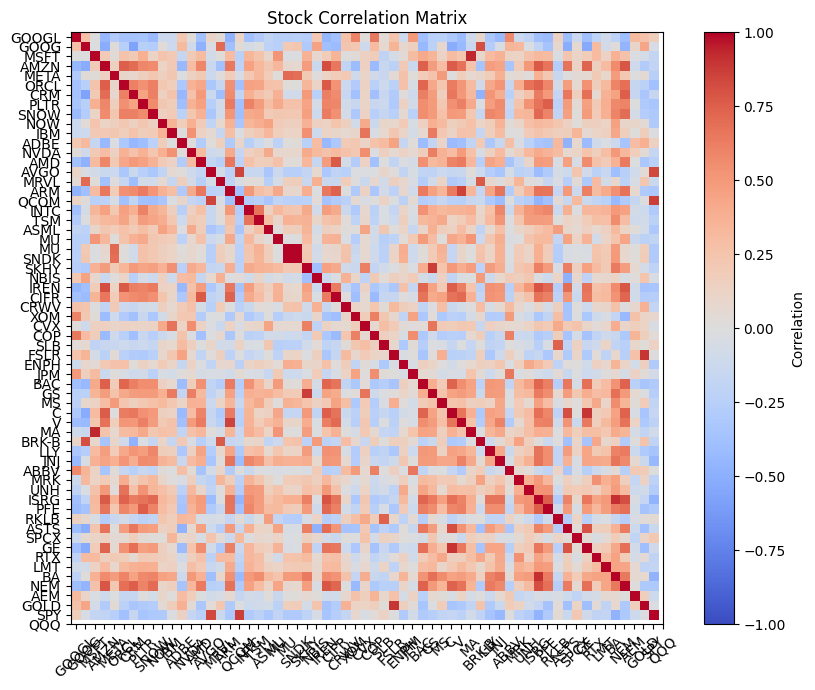

In [8]:
corr = returns.corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(stocks)), stocks, rotation=45)
plt.yticks(range(len(stocks)), stocks)
plt.title("Stock Correlation Matrix")
plt.tight_layout()
plt.show()

In [9]:
threshold = 0.6

G = nx.Graph()
G.add_nodes_from(stocks)

for i in stocks:
    for j in stocks:
        if i != j and corr.loc[i, j] >= threshold:
            G.add_edge(i, j, weight=corr.loc[i, j])

print("Number of stocks:", G.number_of_nodes())
print("Number of connections:", G.number_of_edges())

Number of stocks: 61
Number of connections: 128


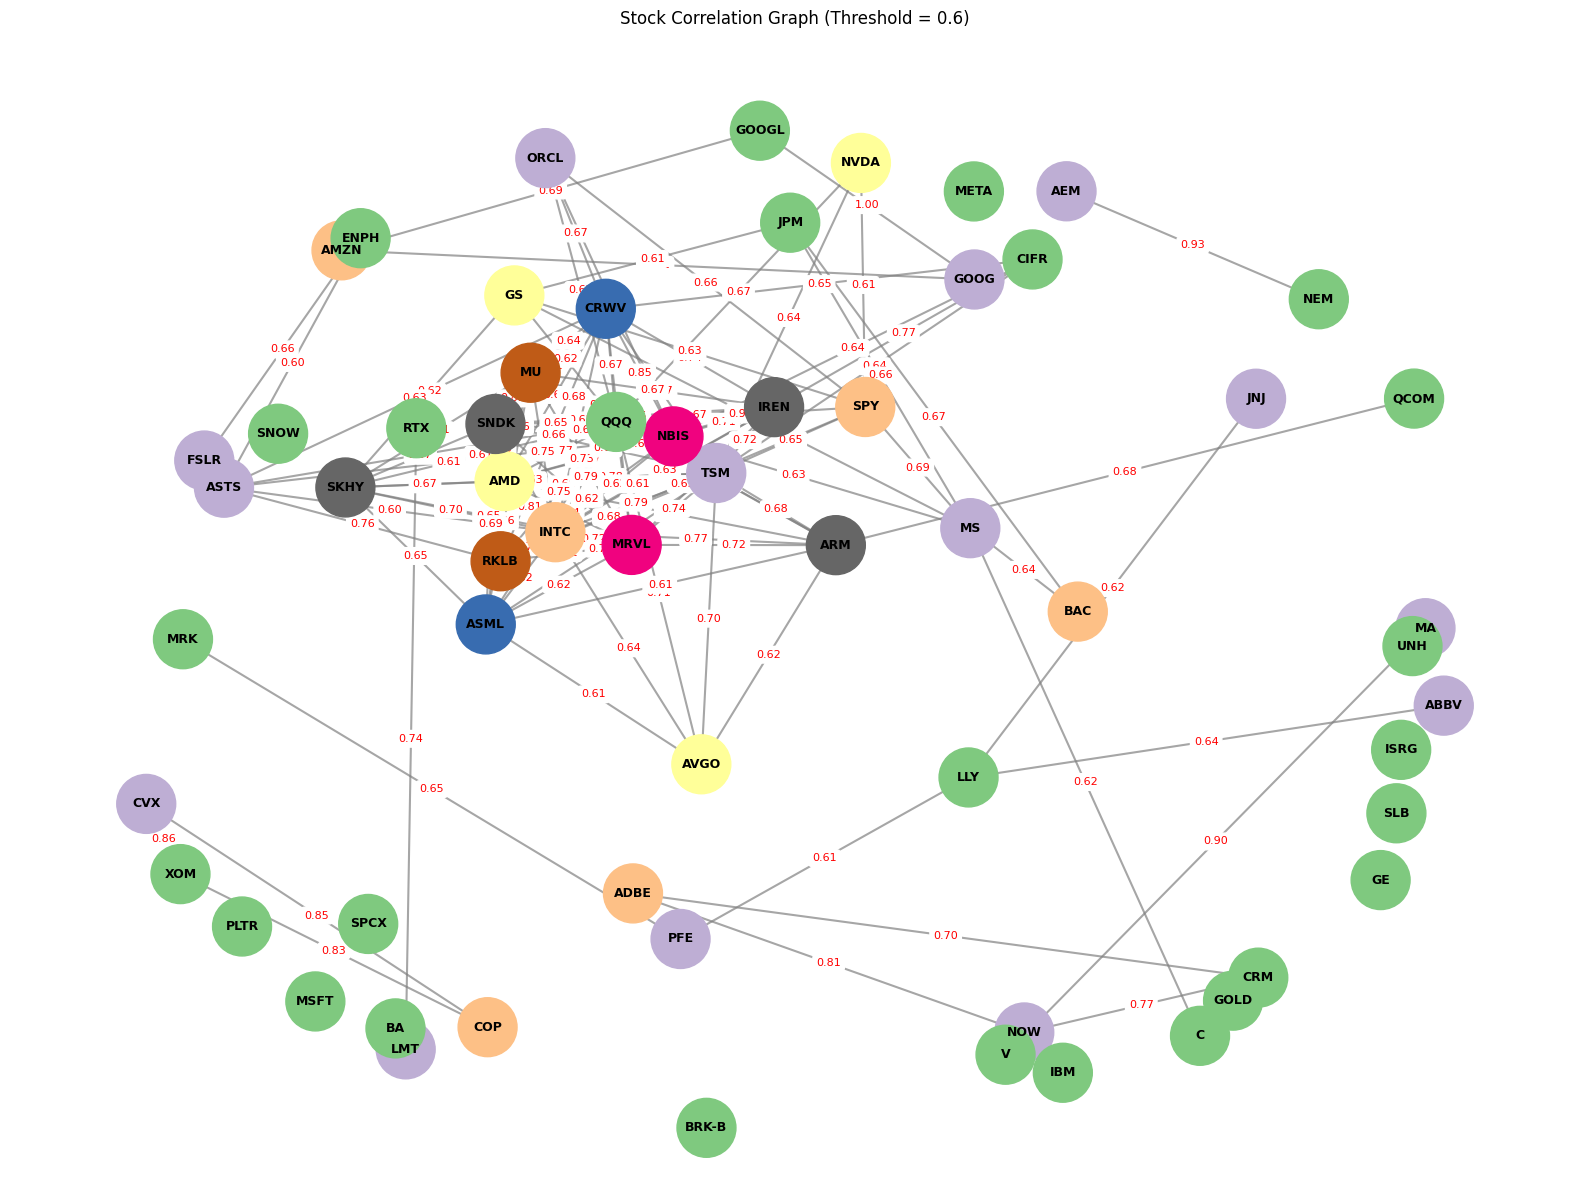

Stock color assignments:
ABBV: Color 1
ADBE: Color 2
AEM: Color 1
AMD: Color 3
AMZN: Color 2
ARM: Color 7
ASML: Color 4
ASTS: Color 1
AVGO: Color 3
BA: Color 0
BAC: Color 2
BRK-B: Color 0
C: Color 0
CIFR: Color 0
COP: Color 2
CRM: Color 0
CRWV: Color 4
CVX: Color 1
ENPH: Color 0
FSLR: Color 1
GE: Color 0
GOLD: Color 0
GOOG: Color 1
GOOGL: Color 0
GS: Color 3
IBM: Color 0
INTC: Color 2
IREN: Color 8
ISRG: Color 0
JNJ: Color 1
JPM: Color 0
LLY: Color 0
LMT: Color 1
MA: Color 1
META: Color 0
MRK: Color 0
MRVL: Color 5
MS: Color 1
MSFT: Color 0
MU: Color 6
NBIS: Color 5
NEM: Color 0
NOW: Color 1
NVDA: Color 3
ORCL: Color 1
PFE: Color 1
PLTR: Color 0
QCOM: Color 0
QQQ: Color 0
RKLB: Color 6
RTX: Color 0
SKHY: Color 8
SLB: Color 0
SNDK: Color 7
SNOW: Color 0
SPCX: Color 0
SPY: Color 2
TSM: Color 1
UNH: Color 0
V: Color 0
XOM: Color 0


In [10]:
colors = nx.coloring.greedy_color(G, strategy="largest_first")
node_colors = [colors[node] for node in G.nodes()]
pos = nx.spring_layout(G, seed=42, k=0.8)

plt.figure(figsize=(16, 12))

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    cmap=plt.cm.Accent, 
    node_size=1800
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_weight="bold"
)

nx.draw_networkx_edges(
    G, pos,
    edge_color="gray",
    width=1.5,
    alpha=0.7
)

edge_labels = nx.get_edge_attributes(G, "weight")
edge_labels = {edge: f"{weight:.2f}" for edge, weight in edge_labels.items()}

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8,
    font_color="red",
    rotate=False
)

plt.title(f"Stock Correlation Graph (Threshold = {threshold})")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Stock color assignments:")
for stock, color in sorted(colors.items()):
    print(f"{stock}: Color {color}")

In [11]:
pairs = []

for i in range(len(stocks)):
    for j in range(i + 1, len(stocks)):
        pairs.append({
            "Stock 1": stocks[i],
            "Stock 2": stocks[j],
            "Correlation": corr.loc[stocks[i], stocks[j]]
        })

results = pd.DataFrame(pairs)
results = results.sort_values("Correlation", ascending=False)

results.head(10)

,Stock 1,Stock 2,Correlation
1071,MU,MU,1.000000
0,GOOGL,GOOG,0.996342
1881,NEM,AEM,0.930620
1890,SPY,QQQ,0.907488
1660,V,MA,0.895283
1111,MU,SNDK,0.891324
1072,MU,SNDK,0.891324
1591,GS,MS,0.869092
1363,XOM,CVX,0.860357
1227,NBIS,CRWV,0.851791
